# HW03 — Probabilistic Models and Particle Filtering

Portfolio edition of the uploaded AI assignment by Behrad Mazaheri. Original prompts and simulation scaffold are retained; the uploaded notebook does not name an assignment author. Added corrections, experiments and the replacement headless maze are documented in README.

Bayesian networks encode a joint distribution and conditional independencies through a directed acyclic graph and conditional probability tables. Edges alone do not establish causality without additional assumptions.


# Section 2: Creating the Model (20 points)

In this section, you will implement this bayesian network using pgmpy library.

Install dependencies using `python -m pip install -r requirements.txt` before running this notebook.


![Original course reference](assets/original-network-diagram.png)

**Model discrepancy:** the supplied image uses a binary Grade and Letter, while the uploaded code uses a three-state Grade and different Letter CPDs. The diagram's Grade row labels also appear inconsistent. This edition keeps the submitted numeric CPDs and evidence order exactly, uses numeric state indices rather than unsupported High/Low labels, and does not claim to reproduce the image's distribution.


In [1]:
SEED = 42
import numpy as np
import pandas as pd
import random
import matplotlib.pyplot as plt
np.random.seed(SEED)
random.seed(SEED)


In [2]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD, State
from pgmpy.sampling import BayesianModelSampling, GibbsSampling
from pgmpy.inference import VariableElimination
import networkx as nx


/workspace/scratch/29499313a261/deps-pgm/pgmpy/estimators/__init__.py:4: FutureWarning: `pgmpy.estimators.StructureScore` is deprecated and will be removed in v1.3.0. Use `pgmpy.structure_score` instead.
  from .StructureScore import (


In [3]:
from pgmpy.models import DiscreteBayesianNetwork
from pgmpy.factors.discrete import TabularCPD

### Section 1: Define the network structure
model = DiscreteBayesianNetwork([
    ('Difficulty', 'Grade'),
    ('Intelligence', 'Grade'),
    ('Intelligence', 'SAT'),
    ('Grade', 'Letter')
])

### Section 2: Define Conditional Probability Distributions (CPDs)

# Difficulty CPD: numeric states 0 and 1
cpd_difficulty = TabularCPD(
    variable='Difficulty',
    variable_card=2,
    values=[[0.6], [0.4]]  # P(0)=0.6, P(1)=0.4
)

cpd_intelligence = TabularCPD(
    variable='Intelligence',
    variable_card=2,
    values=[[0.7], [0.3]]  # Numeric states 0 and 1
)

# Grade has states 0, 1 and 2; numbers preserved from uploaded code
cpd_grade = TabularCPD(
    variable='Grade',
    variable_card=3,
    values=[
        # Columns: (Difficulty, Intelligence) = (0,0), (0,1), (1,0), (1,1)
        [0.3,              0.05,      0.9,       0.5],  # Grade=A
        [0.4,              0.25,      0.08,      0.3],  # Grade=B
        [0.3,              0.7,       0.02,      0.2]   # Grade=C
    ],
    evidence=['Difficulty', 'Intelligence'],
    evidence_card=[2, 2]
)

cpd_letter = TabularCPD(
    variable='Letter',
    variable_card=2,
    values=[
        # Grade=0,1,2
        [0.9,      0.6,  0.1],  # P(Letter=0|Grade)
        [0.1,      0.4,  0.9]   # P(Letter=1|Grade)
    ],
    evidence=['Grade'],
    evidence_card=[3]
)

cpd_sat = TabularCPD(
    variable='SAT',
    variable_card=2,
    values=[
        # Intelligence=0,1
        [0.95,     0.2],  # P(SAT=0|Intelligence)
        [0.05,     0.8]   # P(SAT=1|Intelligence)
    ],
    evidence=['Intelligence'],
    evidence_card=[2]
)

model.add_cpds(cpd_difficulty, cpd_intelligence, cpd_grade, cpd_letter, cpd_sat)

assert model.check_model()

print("Model validated successfully with nodes:", model.nodes())
print("Model edges:", model.edges())

Model validated successfully with nodes: ['Difficulty', 'Grade', 'Intelligence', 'SAT', 'Letter']
Model edges: [('Difficulty', 'Grade'), ('Grade', 'Letter'), ('Intelligence', 'Grade'), ('Intelligence', 'SAT')]


In [4]:
exact_inference = VariableElimination(model)
exact_grade = exact_inference.query(["Grade"], show_progress=False).values
exact_conditional = exact_inference.query(["Intelligence"], evidence={"Letter": 0}, show_progress=False).values
print("Exact P(Grade):", exact_grade)
print("Exact P(Intelligence | Letter=0):", exact_conditional)


Exact P(Grade): [0.447  0.2714 0.2816]
Exact P(Intelligence | Letter=0): [0.78813416 0.21186584]


# Section 3: Operations (10 points)

Use the appropriate functions to answer the questions

The following queries distinguish open paths from collider paths. Difficulty and Intelligence are independent roots, but observing a descendant of their common child Grade opens a path between them.


1. What are the active trail nodes for *Intelligence*?

In [5]:
# 3-1  active-trail nodes
active_trails_intel = model.active_trail_nodes("Intelligence")["Intelligence"]
print("Active-trail nodes for Intelligence:", sorted(active_trails_intel))


Active-trail nodes for Intelligence: ['Grade', 'Intelligence', 'Letter', 'SAT']


2. Are *Difficulty* and *Intelligence* D-connected? What if we have *Letter* as evidence?

In [6]:
# Step 2 – D-connected or not?
no_evidence = model.is_dconnected("Difficulty", "Intelligence")
with_letter  = model.is_dconnected("Difficulty", "Intelligence",
                                   observed=["Letter"])

print("D-connected (no evidence):", no_evidence)
print("D-connected given Letter :", with_letter)


D-connected (no evidence): False
D-connected given Letter : True


3. Print all independencies.

In [7]:
# 3-3  independencies implied by the BN
print("Independencies encoded by the BN:")

indep_obj = model.get_independencies()          # returns an Independencies object
for stmt in indep_obj.get_assertions():         # or:  indep_obj.independencies
    print(" ", stmt)


Independencies encoded by the BN:
  (Grade ⟂ SAT | Intelligence)
  (Difficulty ⟂ Intelligence)
  (Difficulty ⟂ Letter | Grade)
  (Intelligence ⟂ Letter | Grade)
  (Letter ⟂ SAT | Intelligence)
  (Difficulty ⟂ SAT)


# Section 4: Variable Elimination (20 points)

Get the induced graph formed by running Variable Elimination on the network. Print the induced graph and the elimination order.

In [8]:
# Deterministic weighted min-fill order on the current moral graph.
def weighted_min_fill_order(model):
    work = nx.Graph(model.moralize())
    cardinality = model.get_cardinality()
    order = []
    while work.nodes:
        def score(node):
            neighbors = sorted(work.neighbors(node))
            return sum(cardinality[u] * cardinality[v]
                       for i, u in enumerate(neighbors) for v in neighbors[i+1:]
                       if not work.has_edge(u, v))
        node = min(work.nodes, key=lambda node: (score(node), str(node)))
        neighbors = sorted(work.neighbors(node))
        work.add_edges_from((u, v) for i, u in enumerate(neighbors) for v in neighbors[i+1:])
        work.remove_node(node)
        order.append(node)
    return order

def induced_graph(model, order):
    if len(order) != len(model.nodes) or set(order) != set(model.nodes):
        raise ValueError("Order must contain each variable exactly once")
    induced = nx.Graph(model.moralize())
    work = induced.copy()
    for node in order:
        neighbors = sorted(work.neighbors(node))
        fill = [(u, v) for i, u in enumerate(neighbors) for v in neighbors[i+1:]]
        work.add_edges_from(fill)
        induced.add_edges_from(fill)
        work.remove_node(node)
    return induced

order = weighted_min_fill_order(model)
induced = induced_graph(model, order)
print("Elimination order:", order)
print("Induced graph edges:", sorted(tuple(sorted(edge)) for edge in induced.edges()))
print("Induced width:", exact_inference.induced_width(order))


Elimination order: ['Difficulty', 'Letter', 'Grade', 'Intelligence', 'SAT']
Induced graph edges: [('Difficulty', 'Grade'), ('Difficulty', 'Intelligence'), ('Grade', 'Intelligence'), ('Grade', 'Letter'), ('Intelligence', 'SAT')]
Induced width: 2


# Section 5: Sampling (30 points)

Try forward sampling on your model.

In [9]:
def forward_sampling(model, num_samples=10000, seed=SEED):
    return BayesianModelSampling(model).forward_sample(size=num_samples, seed=seed, show_progress=False, n_jobs=1)

forward_samples = forward_sampling(model)
print(forward_samples.head())


   Difficulty  Grade  Intelligence  SAT  Letter
0           0      1             0    0       0
1           1      0             0    0       0
2           1      0             0    0       0
3           0      1             0    0       0
4           0      0             0    0       0


Try likelihood weighting sampling on your model.

In [10]:
def likelihood_weighting_sampling(model, num_samples=10000, evidence=None, seed=SEED + 1):
    evidence = [] if evidence is None else evidence
    return BayesianModelSampling(model).likelihood_weighted_sample(size=num_samples, evidence=evidence, seed=seed, show_progress=False, n_jobs=1)

letter_evidence = [State("Letter", 0)]
weighted_samples = likelihood_weighting_sampling(model, evidence=letter_evidence)
print(weighted_samples.head())


   Difficulty  Grade  Intelligence  SAT  Letter  _weight
0           0      2             0    0       0      0.1
1           1      0             0    0       0      0.9
2           0      2             0    0       0      0.1
3           0      1             1    1       0      0.6
4           0      1             0    0       0      0.6


Try rejection sampling on your model.

In [11]:
def rejection_sampling(model, num_samples=10000, evidence=None, seed=SEED + 2):
    evidence = [] if evidence is None else evidence
    return BayesianModelSampling(model).rejection_sample(size=num_samples, evidence=evidence, seed=seed, show_progress=False)

rejection_samples = rejection_sampling(model, evidence=letter_evidence)
print(rejection_samples.head())


   Difficulty  Grade  Intelligence  SAT  Letter
0           0      2             0    0       0
1           1      0             0    1       0
2           0      1             1    1       0
3           0      0             0    0       0
4           1      0             0    0       0


And finally, try Gibbs sampling.

In [12]:
# Gibbs samples are correlated. Discard the first 1000 iterations as burn-in.
gibbs_samples = GibbsSampling(model).sample(size=11000, seed=SEED + 3).iloc[1000:]
print(gibbs_samples.head())

def empirical_distribution(samples, variable, cardinality, weighted=False):
    weights = samples["_weight"].to_numpy() if weighted else np.ones(len(samples))
    if weights.sum() <= 0:
        raise ValueError("Weights must have positive total")
    return np.bincount(samples[variable].to_numpy(dtype=int), weights=weights, minlength=cardinality) / weights.sum()

sampling_comparison = {
    "forward_grade": empirical_distribution(forward_samples, "Grade", 3),
    "gibbs_grade": empirical_distribution(gibbs_samples, "Grade", 3),
    "likelihood_weighting_intelligence_given_letter0": empirical_distribution(weighted_samples, "Intelligence", 2, weighted=True),
    "rejection_intelligence_given_letter0": empirical_distribution(rejection_samples, "Intelligence", 2),
}
for name, estimate in sampling_comparison.items():
    target = exact_grade if name.endswith("grade") else exact_conditional
    print(name, estimate, "max absolute error:", float(np.max(np.abs(estimate-target))))


      Difficulty  Grade  Intelligence  SAT  Letter
1000           0      1             0    0       1
1001           0      2             0    0       1
1002           0      1             0    0       1
1003           0      2             0    0       1
1004           0      2             0    0       1
forward_grade [0.4377 0.2741 0.2882] max absolute error: 0.00930000000000003
gibbs_grade [0.4624 0.2677 0.2699] max absolute error: 0.01539999999999997
likelihood_weighting_intelligence_given_letter0 [0.79385605 0.20614395] max absolute error: 0.0057218844716862005
rejection_intelligence_given_letter0 [0.7878 0.2122] max absolute error: 0.00033416484072140706


100%|##########| 10999/10999 [00:03<00:00, 3332.43it/s]


Provide a detailed explanation of the results and consider which approach would be most suitable for your model.

For unconditional samples, forward sampling is a natural fit because the graph is a small DAG with explicit CPDs. Gibbs sampling approaches the same marginals but its samples are correlated and require attention to mixing. Rejection sampling keeps draws consistent with Letter=0, while likelihood weighting clamps that evidence and weights draws by its likelihood. Weighted estimates must use `_weight`; simple counts would be incorrect. For this five-variable model, exact Variable Elimination is inexpensive and provides a reference for each approximation. These fixed-seed experiments illustrate sampling error, not guaranteed error bounds.


# Section 6: Particle Filter Simulation

The uploaded simulation scaffold estimates a robot's position from nearest-beacon distance in a 2D maze. Its `draw.py` dependency was absent. This edition supplies `maze.py`, a new headless geometry and plotting implementation with continuous coordinates, cell-center beacons and Euclidean sensor distances.

Particles are weighted by `exp(-(measured-predicted)^2 / (2 * 0.9^2))`, normalized, resampled and propagated. Sensor noise is the submitted uniform ±0.02 noise, so the Gaussian weighting kernel is deliberately broader than the actual sensor noise. With known orientation, the simulation shares the robot heading with the particles; it does not share the robot position. The 95% concentration flag is a heuristic and does not prove correct localization. Symmetric distances can create multiple modes whose weighted mean lies in a wall or an unlikely location. We therefore report position error rather than assuming convergence.


In [13]:
from __future__ import absolute_import

import random
import math
import bisect


In [14]:

# ------------------------------------------------------------------------
# Maze configuration:
# 0 - Empty cell
# 1 - Wall or occupied cell
# 2 - Beacon cell: sensor-detectable, helps robot localize

maze_layout = (
    (1, 1, 0, 0, 2, 0, 0, 0, 0, 1),
    (1, 2, 0, 0, 1, 1, 0, 0, 0, 0),
    (0, 1, 1, 0, 0, 0, 0, 1, 0, 1),
    (0, 0, 0, 0, 1, 0, 0, 1, 1, 2),
    (1, 1, 0, 1, 1, 2, 0, 0, 1, 0),
    (1, 1, 1, 0, 1, 1, 1, 0, 2, 0),
    (2, 0, 0, 0, 0, 0, 0, 0, 0, 0),
    (1, 2, 0, 1, 1, 1, 1, 0, 0, 0),
    (0, 0, 0, 0, 1, 0, 0, 0, 1, 0),
    (0, 0, 1, 0, 0, 2, 1, 1, 1, 0)
)

PARTICLE_TOTAL = 2000
ROBOT_KNOWS_ORIENTATION = True


In [15]:
# ------------------------------------------------------------------------
# Utility functions
import random

def apply_noise(noise_level, *values):
    """
    Adds uniform noise in the range [-noise_level , +noise_level] to
    each supplied value and returns the perturbed result(s).

    If a single value is passed, the single noisy value is returned.
    If multiple values are passed, a tuple of noisy values is returned.
    """
    noisy_vals = [v + random.uniform(-noise_level, noise_level) for v in values]
    return noisy_vals[0] if len(noisy_vals) == 1 else tuple(noisy_vals)


def slight_noise(*values):
    # Applies small noise (used for robot sensing)
    return apply_noise(0.02, *values)

def moderate_noise(*values):
    # Applies more noticeable noise (used during resampling)
    return apply_noise(0.1, *values)

# Standard deviation squared for Gaussian weight calculation
sigma_squared = 0.9 ** 2
# Standard-deviation-squared already defined: sigma_squared = 0.9**2

def gaussian_weight(measured, predicted):
    """
    Computes a Gaussian likelihood weight based on the squared error
    between a measured sensor value and the particle’s predicted value.
    """
    diff2 = (measured - predicted) ** 2
    return math.exp(-diff2 / (2 * sigma_squared))



def estimate_mean_position(particles):
    """
    Returns (mean_x , mean_y , is_confident)

    mean_x , mean_y  : weighted average of particle positions.
    is_confident     : True if at least 95 % of particles lie within
                       a small radius (0.2 cells) of the mean.
    """
    total_w = sum(p.w for p in particles) or 1.0  # simulation regenerates particles before zero-weight estimation
    mean_x = sum(p.x * p.w for p in particles) / total_w
    mean_y = sum(p.y * p.w for p in particles) / total_w

    close_particles = sum(
        1 for p in particles
        if math.hypot(p.x - mean_x, p.y - mean_y) < 0.2
    )
    is_confident = close_particles >= len(particles) * 0.95 and len(particles) > 0
    return mean_x, mean_y, is_confident



In [16]:
class WeightedSampler:
    def __init__(self, states):
        self.valid_states = [s for s in states if math.isfinite(s.w) and s.w > 0]
        total = sum(s.w for s in self.valid_states)
        if total <= 0:
            raise ValueError("No positive finite particle weights")
        self.cumulative_weights = []
        cumulative = 0.0
        for state in self.valid_states:
            cumulative += state.w / total
            self.cumulative_weights.append(cumulative)
        self.cumulative_weights[-1] = 1.0

    def sample(self):
        index = min(bisect.bisect_right(self.cumulative_weights, random.random()), len(self.valid_states)-1)
        return self.valid_states[index]


In [17]:
class Particle(object):
    """
    Represents a single particle with position, heading (angle), and weight.
    """
    def __init__(self, x, y, heading=None, w=1, noisy=False):
        if heading is None:
            heading = random.uniform(0, 360)
        if noisy:
            x, y, heading = moderate_noise(x, y, heading)
        self.x = x
        self.y = y
        self.h = heading  # heading in degrees
        self.w = w        # weight

    def __repr__(self):
        return f"({self.x:.2f}, {self.y:.2f}, w={self.w:.3f})"

    @property
    def xy(self):
        return self.x, self.y

    @property
    def xyh(self):
        return self.x, self.y, self.h

    @classmethod
    def initialize_particles(cls, count, maze):
        # Create a list of particles in random free cells
        return [cls(*maze.random_free_place()) for _ in range(count)]

    def sense(self, maze):
        # Return the true (non-noisy) distance to nearest beacon
        return maze.distance_to_nearest_beacon(*self.xy)

    def attempt_move(self, speed, move_check=None, noisy=False):
        """
        Try to move forward by 'speed' in the direction of heading.
        If 'noisy' is True, adds small random deviation.
        Only move if 'move_check' returns True for new location.
        """

        heading = self.h + random.uniform(-3, 3) if noisy else self.h
        rad = math.radians(heading)
        dx = speed * math.cos(rad)
        dy = speed * math.sin(rad)

        new_x, new_y = self.x + dx, self.y + dy
        if move_check is None or move_check(self, dx, dy):
            self.x += dx
            self.y += dy
            return True
        return False



In [18]:
# ------------------------------------------------------------------------
class Robot(Particle):
    """
    The robot inherits from Particle but uses noisy sensing and random motion.
    """
    speed = 0.1

    def __init__(self, maze):
        super(Robot, self).__init__(*maze.random_free_place(), heading=90)
        self.pick_new_heading()
        self.steps_taken = 0

    def pick_new_heading(self):
        self.h = random.uniform(0, 360)

    def sense(self, maze):
        # Sense distance with added noise
        return slight_noise(super().sense(maze))

    def move_randomly(self, maze):
        # Move in random direction until move is successful
        for _ in range(1000):
            self.steps_taken += 1
            if self.attempt_move(self.speed, noisy=True,
                move_check=lambda r, dx, dy: maze.is_free(r.x+dx, r.y+dy)):
                return
            self.pick_new_heading()
        raise RuntimeError("Robot could not find a legal move")


Particle filter initial / final position error: 2.847297016433192 0.1553888621797503
Particle filter position RMSE: 1.2752155870879704


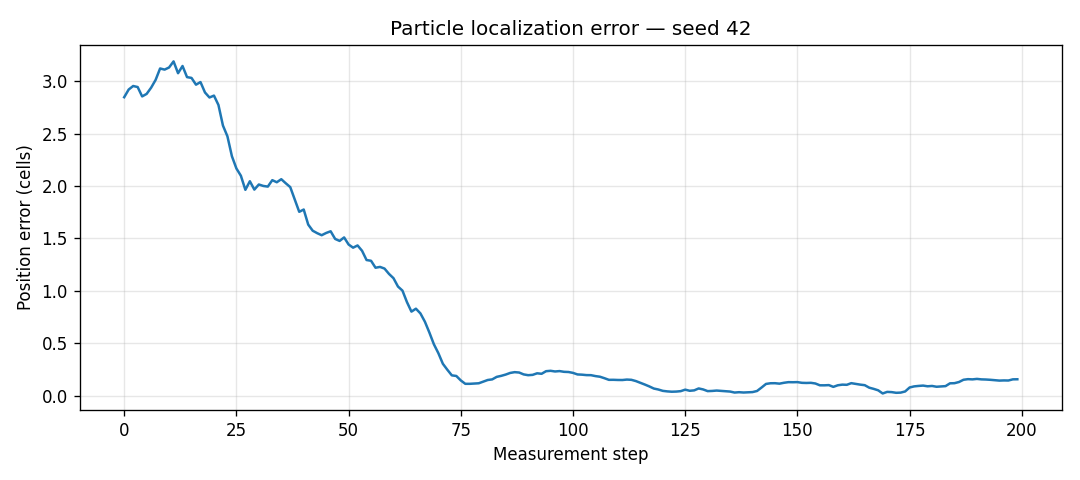

In [19]:
from maze import Maze

def run_particle_filter_simulation(steps=200, count=PARTICLE_TOTAL, seed=SEED, snapshot_path=None):
    random.seed(seed)
    world = Maze(maze_layout)
    particles = Particle.initialize_particles(count, world)
    robot = Robot(world)
    history = []
    for step in range(steps):
        reading = robot.sense(world)
        for particle in particles:
            particle.w = gaussian_weight(reading, particle.sense(world)) if world.is_free(*particle.xy) else 0.0
        total = sum(p.w for p in particles)
        if total <= 0:
            particles = Particle.initialize_particles(count, world)
            for particle in particles:
                particle.w = gaussian_weight(reading, particle.sense(world))
            total = sum(p.w for p in particles)
        for particle in particles:
            particle.w /= total
        mean_x, mean_y, confident = estimate_mean_position(particles)
        history.append({"step": step, "robot_x": robot.x, "robot_y": robot.y,
                        "mean_x": mean_x, "mean_y": mean_y, "confident": confident,
                        "position_error": math.hypot(mean_x-robot.x, mean_y-robot.y),
                        "effective_sample_size": 1 / sum(p.w*p.w for p in particles)})
        if step == steps - 1:
            if snapshot_path:
                world.save_snapshot(particles, robot, (mean_x, mean_y), snapshot_path)
            break
        sampler = WeightedSampler(particles)
        new_particles = []
        for _ in range(count):
            prototype = sampler.sample()
            child = Particle(prototype.x, prototype.y, heading=prototype.h, noisy=True)
            if not world.is_free(*child.xy):
                child = Particle(prototype.x, prototype.y, heading=prototype.h)
            new_particles.append(child)
        particles = new_particles  # The original code forgot to install the resampled population.
        previous_heading = robot.h
        robot.move_randomly(world)
        delta_heading = robot.h - previous_heading
        for particle in particles:
            if ROBOT_KNOWS_ORIENTATION:
                particle.h = robot.h
            else:
                particle.h += delta_heading
            particle.attempt_move(robot.speed, move_check=lambda p, dx, dy: world.is_free(p.x+dx, p.y+dy), noisy=True)
    return history

particle_history = run_particle_filter_simulation(snapshot_path="results/localization_snapshot.png")
errors = [row["position_error"] for row in particle_history]
print("Particle filter initial / final position error:", errors[0], errors[-1])
print("Particle filter position RMSE:", float(np.sqrt(np.mean(np.square(errors)))))
plt.figure(figsize=(9,4))
plt.plot(errors)
plt.xlabel("Measurement step")
plt.ylabel("Position error (cells)")
plt.title("Particle localization error — seed 42")
plt.grid(alpha=0.3)
plt.tight_layout()
plt.savefig("results/localization_error.png", dpi=140)
plt.show()


## Revision provenance

The headless maze, seeded experiments, quantitative comparisons, explanations and correctness fixes were added during portfolio preparation. The original CPD numbers were preserved. This edition is not an unchanged original submission.
